# CIFAR-100-LT: Confidence-Based Data Filtering

This experiment tests whether removing difficult training examples improves image classification on the long-tailed CIFAR-100 dataset.

The procedure uses five stratified training folds, five CNNs, and five ResNet-18 models. Each initial model randomly draws four folds with replacement. For every training image, one CNN and one ResNet-18 that did not train on its fold produce out-of-fold predictions. Images misclassified by both models with low probability for their true labels are considered for removal, subject to a per-class limit.

Finally, fresh CNN and ResNet-18 models are trained separately on the original and filtered training sets and evaluated on the same held-out validation set. There are 14 training runs in total: ten initial models and four final models.

## 1. Environment and settings

Activate the virtual environment and install PyTorch and torchvision with the appropriate GPU support. Install the remaining packages with:

```bash
python -m pip install kagglehub numpy pandas pillow matplotlib scikit-learn tqdm jupyter ipykernel
```

Training settings, random seeds, output paths, and the rejection threshold are defined below. Use a different `SAVE_DIR` when changing experiment settings, so that checkpoints from separate runs do not get mixed.


In [ ]:
import os
import gc
import json
import random
from pathlib import Path

import kagglehub

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score,
    precision_recall_fscore_support, roc_auc_score, average_precision_score
)

# ----- Edit these settings -----
SAVE_DIR = Path('./cifar100_lt_simple_runs').resolve()
SEED = 42
VALIDATION_SIZE = 0.20
FOLDS = 5
MODELS_EACH = 5                 # 5 CNN + 5 ResNet-18
DRAWS_PER_MODEL = 4             # Fold sampling WITH replacement
FOLD_EPOCHS = 12
FINAL_EPOCHS = 15
BATCH_SIZE = 128
NUM_WORKERS = 0                 # Safest for notebooks/Windows; try 2-4 for speed
LEARNING_RATES = {'cnn': 0.001, 'resnet18': 0.0005}

TRUE_PROB_THRESHOLD = 0.05      # Both models must give the TRUE class <= 5%
MAX_REJECT_PER_CLASS = 0.10     # Reject at most 10% of any class
MIN_KEEP_PER_CLASS = 5          # Never remove the last few examples of a class

# ----- GPU selection -----
if torch.cuda.is_available():
    DEVICE = torch.device('cuda')
elif torch.backends.mps.is_available():
    DEVICE = torch.device('mps')
else:
    DEVICE = torch.device('cpu')

print('Device:', DEVICE)
if DEVICE.type == 'cpu':
    print('Warning: CPU training is much slower. Install GPU-enabled PyTorch if possible.')


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_seed(SEED)
SAVE_DIR.mkdir(parents=True, exist_ok=True)
(SAVE_DIR / 'checkpoints').mkdir(exist_ok=True)
(SAVE_DIR / 'oof').mkdir(exist_ok=True)
(SAVE_DIR / 'results').mkdir(exist_ok=True)

Device: cuda


## 2. Download and prepare CIFAR-100-LT

KaggleHub downloads the competition dataset and returns its local directory. Kaggle authentication and acceptance of competition rules may be required. The provided training labels are converted to integer class IDs. A stratified 80/20 split creates the training pool and the held-out validation set. The competition test images have no labels and are used only for optional predictions.


In [4]:
kagglehub.login()

In [ ]:
# Download CIFAR-100-LT competition data.
# Authenticate with Kaggle in the previous cell if required.

folder = Path(kagglehub.competition_download(
    'cifar100-image-classification-with-long-tail'
))
print('KaggleHub dataset folder:', folder)

# KaggleHub may return a folder with or without a "dataset" subfolder.
data_root = None
for root in [folder / 'dataset', folder]:
    csv_file = root / 'cifar100_lt' / 'data' / 'cifar100_lt.csv'
    if csv_file.exists():
        data_root = root
        csv_path = csv_file
        break

if data_root is None:
    raise FileNotFoundError(
        f'cifar100_lt.csv was not found under {folder}. '
        'Check the downloaded competition files.'
    )

print('CSV path:', csv_path)

all_rows = pd.read_csv(csv_path, header=None, names=['image_path', 'label'],
                       dtype={'label': 'string'})
paths = all_rows['image_path'].str.replace(chr(92), '/', regex=False)
train_rows = all_rows[paths.str.contains('/train/', regex=False)].copy()
test_rows = all_rows[paths.str.contains('/test/', regex=False)].copy()

if train_rows.empty or train_rows['label'].isna().any():
    raise ValueError('Training images/labels were not found in the CSV.')

class_names = sorted(train_rows['label'].unique())
class_to_id = {label: i for i, label in enumerate(class_names)}
NUM_CLASSES = len(class_names)
if NUM_CLASSES != 100:
    raise ValueError(f'Expected 100 classes, found {NUM_CLASSES}.')
train_rows['target'] = train_rows['label'].map(class_to_id).astype(int)

train_pool, val_data = train_test_split(
    train_rows, test_size=VALIDATION_SIZE,
    random_state=SEED, stratify=train_rows['target']
)
train_pool = train_pool.reset_index(drop=True)
val_data = val_data.reset_index(drop=True)
test_rows = test_rows.reset_index(drop=True)
print('Train pool:', len(train_pool), '| Validation:', len(val_data), '| Kaggle test:', len(test_rows))

# Prevent accidental reuse of old checkpoints if any important setting changed.
import hashlib
settings = {
    'dataset_hash': hashlib.sha256(csv_path.read_bytes()).hexdigest(),
    'dataset_folder': str(data_root.resolve()),
    'seed': SEED, 'validation_size': VALIDATION_SIZE,
    'folds': FOLDS, 'models_each': MODELS_EACH, 'draws': DRAWS_PER_MODEL,
    'fold_epochs': FOLD_EPOCHS, 'final_epochs': FINAL_EPOCHS,
    'batch_size': BATCH_SIZE, 'learning_rates': LEARNING_RATES,
    'true_prob_threshold': TRUE_PROB_THRESHOLD,
    'max_reject_per_class': MAX_REJECT_PER_CLASS,
    'min_keep_per_class': MIN_KEEP_PER_CLASS,
}
settings_file = SAVE_DIR / 'settings.json'
if settings_file.exists():
    old_settings = json.loads(settings_file.read_text())
    if settings != old_settings:
        raise ValueError('Settings changed! Set SAVE_DIR to a NEW folder for this experiment.')
else:
    settings_file.write_text(json.dumps(settings, indent=2))

train_pool.to_csv(SAVE_DIR / 'results' / 'training_pool.csv', index=False)
val_data.to_csv(SAVE_DIR / 'results' / 'untouched_validation.csv', index=False)

100%|██████████| 90.4M/90.4M [00:07<00:00, 13.1MB/s]

Extracting files...


KaggleHub dataset folder: /home/sidhant/.cache/kagglehub/competitions/cifar100-image-classification-with-long-tail
CSV path: /home/sidhant/.cache/kagglehub/competitions/cifar100-image-classification-with-long-tail/dataset/cifar100_lt/data/cifar100_lt.csv
Train pool: 22978 | Validation: 5745 | Kaggle test: 9999


## 3. Check the class distribution

Count images per class in the training pool to inspect the long-tailed distribution.


Smallest class: 41 images | Largest class: 399 images


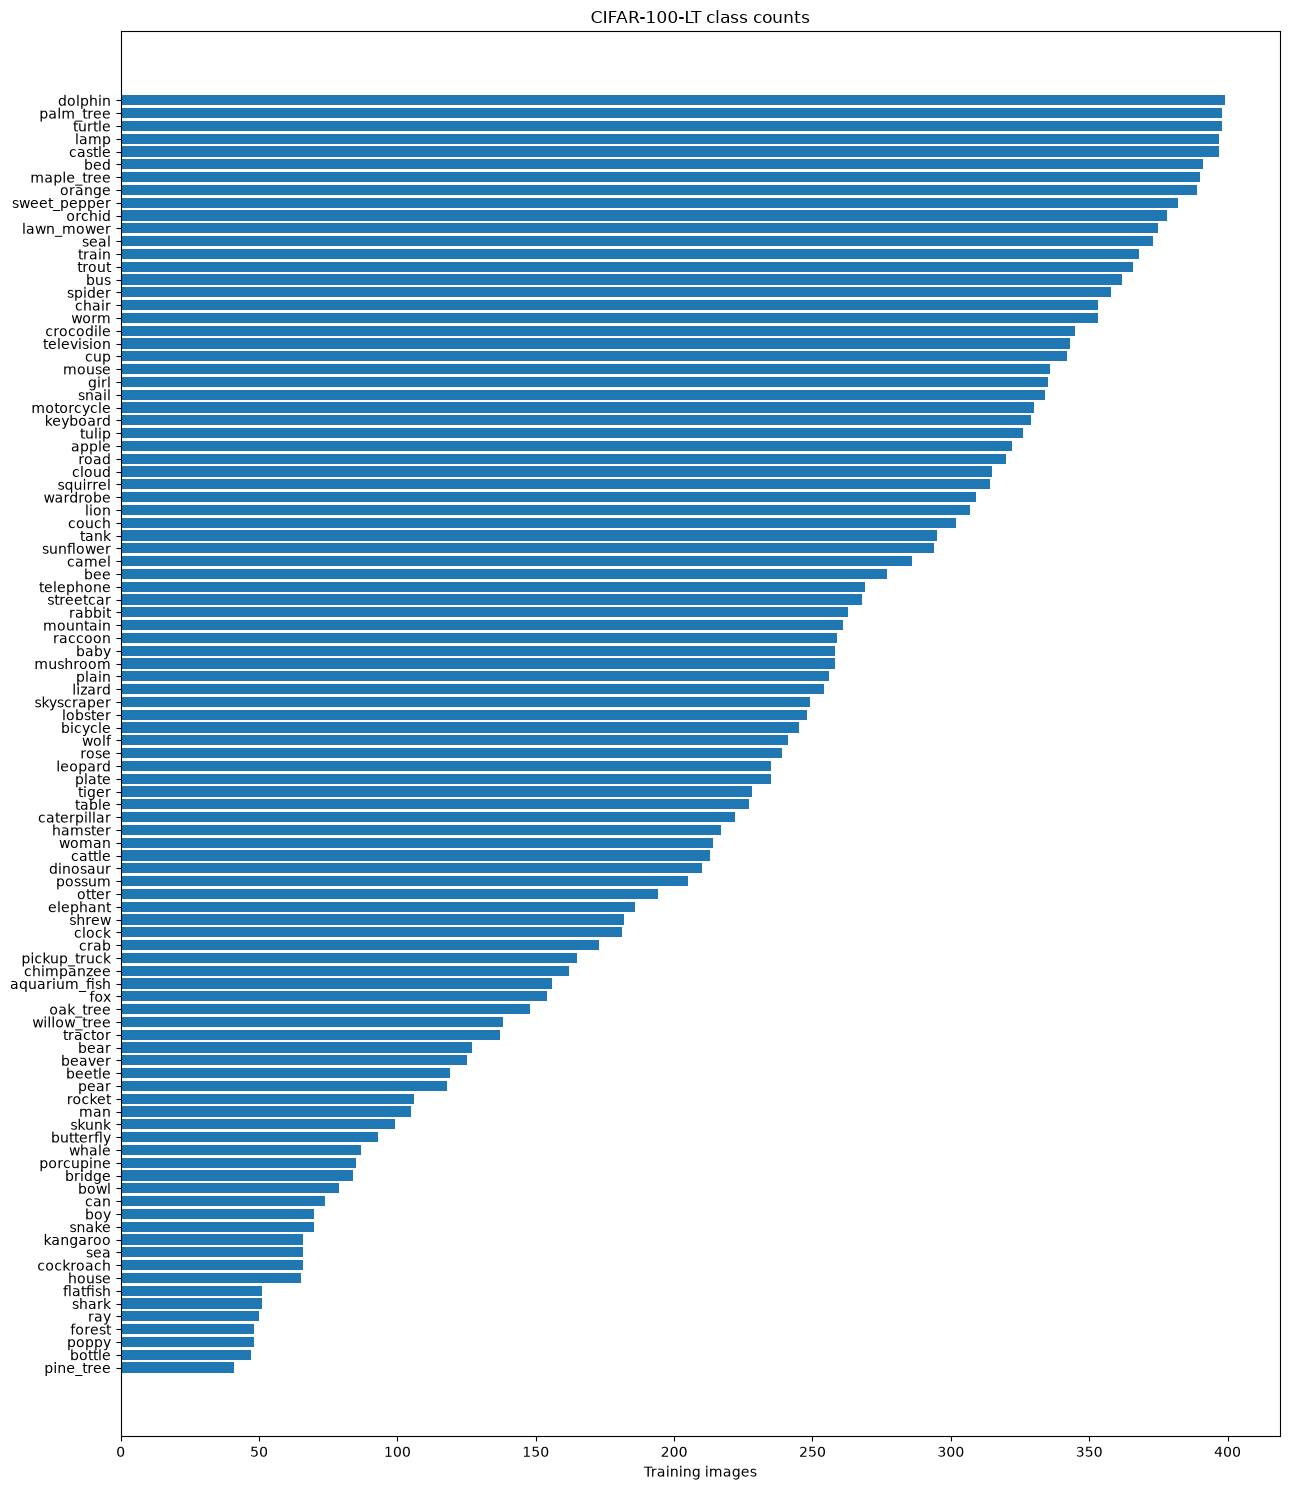

In [7]:
counts = train_pool['label'].value_counts().sort_values()
print('Smallest class:', counts.min(), 'images | Largest class:', counts.max(), 'images')
plt.figure(figsize=(13, 15))
plt.barh([str(x) for x in counts.index], counts.values)
plt.xlabel('Training images')
plt.title('CIFAR-100-LT class counts')
plt.tight_layout()
plt.show()

## 4. Dataset, CNN, ResNet-18

Training images receive random cropping, horizontal flipping, and normalization. Validation and out-of-fold prediction use only deterministic conversion and normalization. The baseline CNN contains three convolutional blocks followed by fully connected layers. ResNet-18 uses a CIFAR-sized first convolution, no initial max-pooling layer, and a 100-class output layer. Both models start with randomly initialized weights.

In [8]:
mean = (0.5071, 0.4867, 0.4408)
std = (0.2675, 0.2565, 0.2761)
train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])
valid_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])


class CIFARDataset(Dataset):
    def __init__(self, table, transform):
        self.paths = [data_root / path for path in table['image_path']]
        self.labels = table['target'].tolist() if 'target' in table else [-1] * len(table)
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, index):
        with Image.open(self.paths[index]) as image:
            image = image.convert('RGB')
        return self.transform(image), self.labels[index]


class SimpleCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 256), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(256, NUM_CLASSES),
        )

    def forward(self, x):
        return self.layers(x)


def make_model(kind):
    if kind == 'cnn':
        return SimpleCNN().to(DEVICE)
    model = models.resnet18(weights=None)
    model.conv1 = nn.Conv2d(3, 64, 3, stride=1, padding=1, bias=False)
    model.maxpool = nn.Identity()
    model.fc = nn.Linear(model.fc.in_features, NUM_CLASSES)
    return model.to(DEVICE)


def make_loader(table, training=False):
    transform = train_transform if training else valid_transform
    return DataLoader(
        CIFARDataset(table, transform), batch_size=BATCH_SIZE,
        shuffle=training, num_workers=NUM_WORKERS,
        pin_memory=(DEVICE.type == 'cuda')
    )


def class_weights(table):
    counts = np.bincount(table['target'], minlength=NUM_CLASSES)
    weights = np.zeros(NUM_CLASSES, dtype=float)
    present = counts > 0
    weights[present] = 1 / np.sqrt(counts[present])
    weights[present] /= weights[present].mean()
    return torch.tensor(weights, dtype=torch.float32, device=DEVICE)

## 5. Training, inference, and checkpoints

Models are trained using weighted cross-entropy and the AdamW optimizer. Class weights are inversely proportional to the square root of the class frequency. Training checkpoints store model parameters, optimizer state, completed epoch, and loss/accuracy history. Prediction uses the softmax probabilities produced by the model.


In [9]:
def train_model(kind, name, data, epochs, seed):
    set_seed(seed)
    model = make_model(kind)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATES[kind], weight_decay=0.01)
    loss_fn = nn.CrossEntropyLoss(weight=class_weights(data))
    loader = make_loader(data, training=True)
    checkpoint = SAVE_DIR / 'checkpoints' / f'{name}.pt'
    history = []
    start_epoch = 0

    if checkpoint.exists():
        saved = torch.load(checkpoint, map_location=DEVICE, weights_only=True)
        model.load_state_dict(saved['model'])
        optimizer.load_state_dict(saved['optimizer'])
        history = saved['history']
        start_epoch = saved['epoch']
        print(f'{name}: resuming at epoch {start_epoch}/{epochs}')

    for epoch in range(start_epoch, epochs):
        # Fixed per-epoch seed also makes checkpoint restarts reproducible.
        set_seed(seed + epoch + 1)
        model.train()
        total_loss = 0.0
        correct = 0
        seen = 0

        for images, labels in tqdm(loader, desc=f'{name}: epoch {epoch+1}/{epochs}', leave=False):
            images = images.to(DEVICE)
            labels = labels.to(DEVICE)
            optimizer.zero_grad()
            outputs = model(images)
            loss = loss_fn(outputs, labels)
            loss.backward()
            optimizer.step()

            total_loss += loss.item() * len(labels)
            correct += (outputs.argmax(1) == labels).sum().item()
            seen += len(labels)

        row = {'epoch': epoch + 1, 'loss': total_loss / seen, 'accuracy': correct / seen}
        history.append(row)
        print(f"{name}: epoch {epoch+1}/{epochs} | loss {row['loss']:.4f} | accuracy {row['accuracy']:.4f}")

        # Save without risking an incomplete final checkpoint.
        temp_path = checkpoint.with_suffix('.tmp')
        torch.save({'model': model.state_dict(), 'optimizer': optimizer.state_dict(),
                    'epoch': epoch + 1, 'history': history}, temp_path)
        os.replace(temp_path, checkpoint)

    pd.DataFrame(history).to_csv(SAVE_DIR / 'results' / f'{name}_training.csv', index=False)
    return model


@torch.inference_mode()
def predict_probs(model, data):
    if len(data) == 0:
        return np.empty((0, NUM_CLASSES), dtype=np.float32)
    model.eval()
    predictions = []
    for images, _ in make_loader(data):
        outputs = model(images.to(DEVICE))
        predictions.append(outputs.softmax(dim=1).cpu().numpy())
    return np.concatenate(predictions)


def free_model(model):
    model.to('cpu')  # Release the model's GPU weights before clearing the cache.
    gc.collect()
    if DEVICE.type == 'cuda':
        torch.cuda.empty_cache()
    elif DEVICE.type == 'mps':
        torch.mps.empty_cache()

## 6. Split into 5 folds; randomly sample folds for 5 CNNs + 5 ResNets

The **four fold numbers per model are sampled with replacement**. For example, `[1, 1, 3, 5]` means the model trains twice on fold 1 and once each on folds 3 and 5; it **never saw folds 2 and 4**.

We retry a random draw until every fold has at least one eligible CNN and one eligible ResNet, and each model sees at least three different folds. This is necessary to ensure that every image can receive two genuine out-of-fold predictions.

In [10]:
# Give each image one of five fold numbers (0, 1, 2, 3, or 4).
fold_id = np.full(len(train_pool), -1, dtype=int)
splitter = StratifiedKFold(n_splits=FOLDS, shuffle=True, random_state=SEED)
for fold, (_, held_out) in enumerate(splitter.split(train_pool, train_pool['target'])):
    fold_id[held_out] = fold
fold_rows = [np.where(fold_id == fold)[0] for fold in range(FOLDS)]

# Sample training folds WITH replacement, ensuring every held-out fold is covered.
rng = np.random.default_rng(SEED)
plans = {}
for kind in ['cnn', 'resnet18']:
    for _ in range(50000):
        draws = rng.integers(0, FOLDS, size=(MODELS_EACH, DRAWS_PER_MODEL))
        enough_variety = all(len(set(row)) >= 3 for row in draws)
        all_folds_covered = all(any(fold not in row for row in draws) for fold in range(FOLDS))
        if enough_variety and all_folds_covered:
            plans[kind] = draws
            break
    else:
        raise RuntimeError(f'Could not generate an eligible fold plan for {kind}.')

# Randomly choose one eligible CNN and one eligible ResNet FOR EACH IMAGE.
selected = {}
for kind in ['cnn', 'resnet18']:
    selected[kind] = np.full(len(train_pool), -1, dtype=int)
    for fold in range(FOLDS):
        eligible = [m for m in range(MODELS_EACH) if fold not in plans[kind][m]]
        selected[kind][fold_rows[fold]] = rng.choice(eligible, size=len(fold_rows[fold]))

    # A selected model must NEVER train on the image's fold.
    for m in range(MODELS_EACH):
        image_folds = fold_id[selected[kind] == m]
        assert not np.isin(image_folds, plans[kind][m]).any(), 'Fold leakage detected!'

for kind, draws in plans.items():
    for m, row in enumerate(draws):
        print(f'{kind} {m+1}: training folds {row.tolist()}')

(SAVE_DIR / 'results' / 'fold_sampling_plan.json').write_text(
    json.dumps({kind: draws.tolist() for kind, draws in plans.items()}, indent=2)
)
assignments = train_pool[['image_path', 'label']].copy()
assignments['fold'] = fold_id + 1
assignments['chosen_cnn'] = selected['cnn'] + 1
assignments['chosen_resnet18'] = selected['resnet18'] + 1
assignments.to_csv(SAVE_DIR / 'results' / 'image_model_assignments.csv', index=False)
print('All images have two valid out-of-fold model assignments.')

cnn 1: training folds [4, 3, 1, 4]
cnn 2: training folds [2, 1, 4, 1]
cnn 3: training folds [0, 2, 3, 0]
cnn 4: training folds [2, 0, 3, 2]
cnn 5: training folds [1, 1, 2, 3]
resnet18 1: training folds [4, 1, 1, 2]
resnet18 2: training folds [4, 4, 0, 1]
resnet18 3: training folds [4, 0, 4, 1]
resnet18 4: training folds [4, 1, 2, 3]
resnet18 5: training folds [0, 2, 2, 3]
All images have two valid out-of-fold model assignments.


## 7. Train all 10 models and collect out-of-fold probabilities

The model only predicts for the images **assigned to it**. Predictions are cached to disk, so a rerun can skip completed models. A cache entry records its image indices, labels, and training folds for safety.

In [11]:
oof_probs = {
    'cnn': np.full((len(train_pool), NUM_CLASSES), np.nan, dtype=np.float32),
    'resnet18': np.full((len(train_pool), NUM_CLASSES), np.nan, dtype=np.float32),
}

for kind in ['cnn', 'resnet18']:
    for m in range(MODELS_EACH):
        draws = plans[kind][m]
        name = f'fold_{kind}_{m+1}'
        # Concatenation repeats a fold if it was sampled twice.
        training_indices = np.concatenate([fold_rows[f] for f in draws])
        prediction_indices = np.where(selected[kind] == m)[0]
        assert not np.isin(fold_id[prediction_indices], draws).any()

        training_data = train_pool.iloc[training_indices].reset_index(drop=True)
        prediction_data = train_pool.iloc[prediction_indices].reset_index(drop=True)
        cache = SAVE_DIR / 'oof' / f'{name}.npz'

        if cache.exists():
            with np.load(cache) as saved:
                assert np.array_equal(saved['indices'], prediction_indices)
                assert np.array_equal(saved['labels'], prediction_data['target'].to_numpy())
                assert np.array_equal(saved['draws'], draws)
                probs = saved['probs']
            print(name, ': cached predictions loaded')
        else:
            print(f'{name}: train {len(training_data)} rows, predict {len(prediction_data)} held-out rows')
            model = train_model(kind, name, training_data, FOLD_EPOCHS,
                                seed=SEED + (100 if kind == 'cnn' else 200) + m)
            probs = predict_probs(model, prediction_data)
            # Atomic NPZ save, so interrupted writes cannot damage the old cache.
            temp_cache = cache.with_suffix('.tmp.npz')
            np.savez_compressed(temp_cache, indices=prediction_indices,
                                labels=prediction_data['target'].to_numpy(),
                                draws=draws, probs=probs)
            os.replace(temp_cache, cache)
            free_model(model)

        oof_probs[kind][prediction_indices] = probs

for kind in ['cnn', 'resnet18']:
    assert np.isfinite(oof_probs[kind]).all(), f'Missing OOF predictions for {kind}'
    assert np.allclose(oof_probs[kind].sum(axis=1), 1, atol=0.001)
print('Both out-of-fold probability tables are complete.')

fold_cnn_1: train 18381 rows, predict 6162 held-out rows


fold_cnn_1: epoch 1/12:   0%|          | 0/144 [00:00<?, ?it/s]

fold_cnn_1: epoch 1/12 | loss 4.2777 | accuracy 0.0597


fold_cnn_1: epoch 2/12:   0%|          | 0/144 [00:00<?, ?it/s]

fold_cnn_1: epoch 2/12 | loss 3.8714 | accuracy 0.1173


fold_cnn_1: epoch 3/12:   0%|          | 0/144 [00:00<?, ?it/s]

... (231 outputs left out)

fold_resnet18_5: epoch 11/12:   0%|          | 0/144 [00:00<?, ?it/s]

fold_resnet18_5: epoch 11/12 | loss 1.2843 | accuracy 0.6385


fold_resnet18_5: epoch 12/12:   0%|          | 0/144 [00:00<?, ?it/s]

fold_resnet18_5: epoch 12/12 | loss 1.1592 | accuracy 0.6704
Both out-of-fold probability tables are complete.


## 8. Agree on rejection, then remove only the most suspicious images

An image is a rejection candidate when both assigned models predict the wrong class and each assigns a probability of 0.05 or less to the image's true class. Candidates are ranked within their class by low average true-class probability. At most 10% of examples from a class are removed, and at least five images from each class are retained. This produces the filtered training pool.

This procedure identifies examples that both models find difficult; it does not establish that the removed images have incorrect labels.

**Simple confidence rule:** reject a candidate only if both chosen models (a) predict the wrong class and (b) each assign the true label a probability of at most `TRUE_PROB_THRESHOLD`.

Even when many images satisfy that rule, reject no more than `MAX_REJECT_PER_CLASS` of each class and keep at least `MIN_KEEP_PER_CLASS`. This protects rare classes on the long-tailed dataset.

Both models wrong: 10436
Confidence-based candidates: 4874
Rejected: 2064
Original: 22978 | Filtered: 20914
     class  original  filtered  removed
   dolphin       399       360       39
       bed       391       352       39
 palm_tree       398       359       39
      lamp       397       358       39
    turtle       398       359       39
    orchid       378       341       37
lawn_mower       375       338       37
      seal       373       336       37
     train       368       332       36
     trout       366       330       36


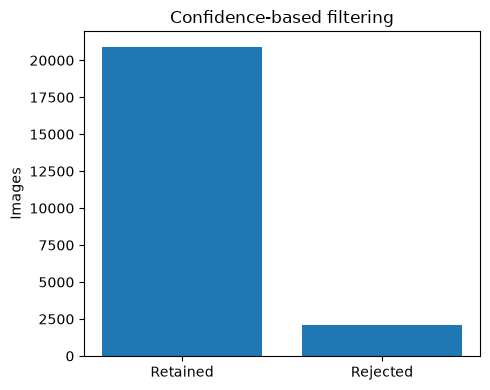

In [12]:
true_labels = train_pool['target'].to_numpy()
indices = np.arange(len(train_pool))
cnn_probs = oof_probs['cnn']
resnet_probs = oof_probs['resnet18']

cnn_pred = cnn_probs.argmax(axis=1)
resnet_pred = resnet_probs.argmax(axis=1)
cnn_true_prob = cnn_probs[indices, true_labels]
resnet_true_prob = resnet_probs[indices, true_labels]

both_wrong = (cnn_pred != true_labels) & (resnet_pred != true_labels)
low_confidence = (cnn_true_prob <= TRUE_PROB_THRESHOLD) & (
    resnet_true_prob <= TRUE_PROB_THRESHOLD)
candidates = both_wrong & low_confidence

# Sort eligible candidates by the two models' average probability of the true class.
risk = 1 - (cnn_true_prob + resnet_true_prob) / 2
rejected = np.zeros(len(train_pool), dtype=bool)
for label in range(NUM_CLASSES):
    class_rows = np.where(true_labels == label)[0]
    class_candidates = class_rows[candidates[class_rows]]
    max_remove = min(
        int(len(class_rows) * MAX_REJECT_PER_CLASS),
        len(class_rows) - MIN_KEEP_PER_CLASS
    )
    max_remove = max(0, max_remove)
    worst_first = class_candidates[np.argsort(-risk[class_candidates])]
    rejected[worst_first[:max_remove]] = True

filtered_pool = train_pool.loc[~rejected].reset_index(drop=True)
print('Both models wrong:', both_wrong.sum())
print('Confidence-based candidates:', candidates.sum())
print('Rejected:', rejected.sum())
print('Original:', len(train_pool), '| Filtered:', len(filtered_pool))

review = assignments.copy()
review['cnn_prediction'] = [class_names[i] for i in cnn_pred]
review['resnet_prediction'] = [class_names[i] for i in resnet_pred]
review['cnn_confidence'] = cnn_probs.max(axis=1)
review['resnet_confidence'] = resnet_probs.max(axis=1)
review['cnn_true_class_probability'] = cnn_true_prob
review['resnet_true_class_probability'] = resnet_true_prob
review['both_wrong'] = both_wrong
review['candidate'] = candidates
review['rejected'] = rejected
review.to_csv(SAVE_DIR / 'results' / 'oof_confidence_and_rejection.csv', index=False)
review.loc[rejected].to_csv(SAVE_DIR / 'results' / 'rejected_examples.csv', index=False)
filtered_pool.to_csv(SAVE_DIR / 'results' / 'filtered_training_pool.csv', index=False)

before = np.bincount(true_labels, minlength=NUM_CLASSES)
after = np.bincount(filtered_pool['target'], minlength=NUM_CLASSES)
rejection_by_class = pd.DataFrame({
    'class': class_names, 'original': before, 'filtered': after,
    'removed': before - after
})
rejection_by_class.to_csv(SAVE_DIR / 'results' / 'rejection_by_class.csv', index=False)
print(rejection_by_class.sort_values('removed', ascending=False).head(10).to_string(index=False))

plt.figure(figsize=(5, 4))
plt.bar(['Retained', 'Rejected'], [len(filtered_pool), int(rejected.sum())])
plt.title('Confidence-based filtering')
plt.ylabel('Images')
plt.tight_layout()
plt.show()

## 9. AUC, precision, recall, F1 and accuracy

We calculate **macro** precision, recall and F1, plus **one-vs-rest multiclass ROC-AUC and PR-AUC**. A missing class is skipped when computing its AUC instead of producing a misleading number.

In [13]:
def evaluate(y_true, probs):
    predicted = probs.argmax(axis=1)
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true, predicted, labels=np.arange(NUM_CLASSES),
        average='macro', zero_division=0
    )

    roc_scores = []
    pr_scores = []
    for label in range(NUM_CLASSES):
        is_class = (y_true == label).astype(int)
        if 0 < is_class.sum() < len(is_class):
            roc_scores.append(roc_auc_score(is_class, probs[:, label]))
            pr_scores.append(average_precision_score(is_class, probs[:, label]))

    return {
        'accuracy': accuracy_score(y_true, predicted),
        'balanced_accuracy': balanced_accuracy_score(y_true, predicted),
        'macro_precision': precision,
        'macro_recall': recall,
        'macro_f1': f1,
        'macro_roc_auc': np.mean(roc_scores) if roc_scores else np.nan,
        'macro_pr_auc': np.mean(pr_scores) if pr_scores else np.nan,
    }


def per_class_scores(y_true, probs, kind, version):
    predicted = probs.argmax(axis=1)
    p, r, f1, counts = precision_recall_fscore_support(
        y_true, predicted, labels=np.arange(NUM_CLASSES), zero_division=0
    )
    rows = []
    for label in range(NUM_CLASSES):
        binary = (y_true == label).astype(int)
        auc = roc_auc_score(binary, probs[:, label]) if 0 < binary.sum() < len(binary) else np.nan
        rows.append({'model': kind, 'data': version, 'class': class_names[label],
                     'support': counts[label], 'precision': p[label],
                     'recall': r[label], 'f1': f1[label], 'roc_auc': auc})
    return rows

## 10. Retrain on original and filtered data (4 new models)

For each architecture, the original and filtered training runs start from **identical initial random weights**, use the same epoch budget, and are evaluated on the **same untouched labeled validation set**. They differ only in their training data.

In [14]:
val_labels = val_data['target'].to_numpy()
results = []
class_results = []

for kind in ['cnn', 'resnet18']:
    for version, data in [('original', train_pool), ('filtered', filtered_pool)]:
        name = f'final_{kind}_{version}'
        print(f'{name}: {len(data)} training images')
        model = train_model(kind, name, data, FINAL_EPOCHS,
                            seed=SEED + (300 if kind == 'cnn' else 400))
        probs = predict_probs(model, val_data)
        np.save(SAVE_DIR / 'results' / f'{name}_validation_probs.npy', probs)

        scores = evaluate(val_labels, probs)
        results.append({'model': kind, 'data': version, 'train_images': len(data), **scores})
        class_results.extend(per_class_scores(val_labels, probs, kind, version))
        print('Macro F1:', round(scores['macro_f1'], 4),
              '| ROC-AUC:', round(scores['macro_roc_auc'], 4))
        free_model(model)

comparison = pd.DataFrame(results)
comparison.to_csv(SAVE_DIR / 'results' / 'model_comparison.csv', index=False)
pd.DataFrame(class_results).to_csv(SAVE_DIR / 'results' / 'per_class_metrics.csv', index=False)
print(comparison.round(4).to_string(index=False))

final_cnn_original: 22978 training images


final_cnn_original: epoch 1/15:   0%|          | 0/180 [00:00<?, ?it/s]

final_cnn_original: epoch 1/15 | loss 4.2002 | accuracy 0.0701


final_cnn_original: epoch 2/15:   0%|          | 0/180 [00:00<?, ?it/s]

final_cnn_original: epoch 2/15 | loss 3.7543 | accuracy 0.1350


final_cnn_original: epoch 3/15:   0%|          | 0/180 [00:00<?, ?it/s]

... (111 outputs left out)

final_resnet18_filtered: epoch 14/15:   0%|          | 0/164 [00:00<?, ?it/s]

final_resnet18_filtered: epoch 14/15 | loss 0.9858 | accuracy 0.7063


final_resnet18_filtered: epoch 15/15:   0%|          | 0/164 [00:00<?, ?it/s]

final_resnet18_filtered: epoch 15/15 | loss 0.9022 | accuracy 0.7285
Macro F1: 0.4759 | ROC-AUC: 0.9703
   model     data  train_images  accuracy  balanced_accuracy  macro_precision  macro_recall  macro_f1  macro_roc_auc  macro_pr_auc
     cnn original         22978    0.3916             0.3437           0.3620        0.3437    0.3347         0.9407        0.3557
     cnn filtered         20914    0.3876             0.3437           0.3436        0.3437    0.3281         0.9360        0.3472
resnet18 original         22978    0.5394             0.4856           0.5265        0.4856    0.4867         0.9728        0.5427
resnet18 filtered         20914    0.5342             0.4844           0.5021        0.4844    0.4759         0.9703        0.5280


## 11. Compare filtered vs. original training

Filtered minus original: positive values mean an improvement.
   model  accuracy  balanced_accuracy  macro_precision  macro_recall  macro_f1  macro_roc_auc  macro_pr_auc
     cnn   -0.0040            -0.0001          -0.0184       -0.0001   -0.0067        -0.0046       -0.0085
resnet18   -0.0052            -0.0013          -0.0244       -0.0013   -0.0108        -0.0025       -0.0147


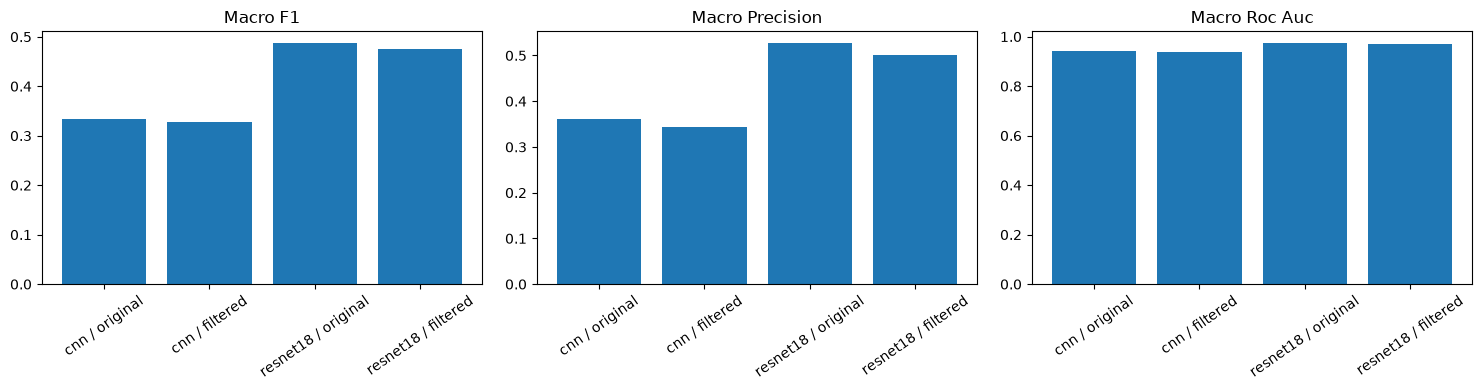

In [15]:
metrics = ['accuracy', 'balanced_accuracy', 'macro_precision',
           'macro_recall', 'macro_f1', 'macro_roc_auc', 'macro_pr_auc']

changes = []
for kind in ['cnn', 'resnet18']:
    rows = comparison[comparison['model'] == kind].set_index('data')
    difference = rows.loc['filtered', metrics] - rows.loc['original', metrics]
    changes.append({'model': kind, **difference.to_dict()})

change_table = pd.DataFrame(changes)
change_table.to_csv(SAVE_DIR / 'results' / 'filtered_minus_original.csv', index=False)
print('Filtered minus original: positive values mean an improvement.')
print(change_table.round(4).to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, metric in zip(axes, ['macro_f1', 'macro_precision', 'macro_roc_auc']):
    labels = comparison['model'] + ' / ' + comparison['data']
    ax.bar(labels, comparison[metric])
    ax.set_title(metric.replace('_', ' ').title())
    ax.tick_params(axis='x', rotation=35)
plt.tight_layout()
plt.savefig(SAVE_DIR / 'results' / 'model_comparison.png', dpi=150)
plt.show()